In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import joblib


# Dataset Loading

In [11]:
bank_df = pd.read_csv("bank-additional-full.csv")

In [12]:
bank_df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


# Data Understanding and Data Quality Checks

In [13]:
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [14]:
bank_df.shape

(41188, 21)

In [15]:
bank_df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [16]:
bank_df.rename(columns={"y": "customer subscribed"}, inplace=True)

C:\Users\Hp\AppData\Local\Temp\ipykernel_9956\3959199862.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bank_df.rename(columns={"y": "customer subscribed"}, inplace=True)


In [17]:
bank_df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'customer subscribed'],
      dtype='str')

In [18]:
bank_df.dtypes

age                      int64
job                        str
marital                    str
education                  str
default                    str
housing                    str
loan                       str
contact                    str
month                      str
day_of_week                str
duration                 int64
campaign                 int64
pdays                    int64
previous                 int64
poutcome                   str
emp.var.rate           float64
cons.price.idx         float64
cons.conf.idx          float64
euribor3m              float64
nr.employed            float64
customer subscribed        str
dtype: object

In [19]:
bank_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  41188 non-null  int64  
 1   job                  41188 non-null  str    
 2   marital              41188 non-null  str    
 3   education            41188 non-null  str    
 4   default              41188 non-null  str    
 5   housing              41188 non-null  str    
 6   loan                 41188 non-null  str    
 7   contact              41188 non-null  str    
 8   month                41188 non-null  str    
 9   day_of_week          41188 non-null  str    
 10  duration             41188 non-null  int64  
 11  campaign             41188 non-null  int64  
 12  pdays                41188 non-null  int64  
 13  previous             41188 non-null  int64  
 14  poutcome             41188 non-null  str    
 15  emp.var.rate         41188 non-null  float64
 1

In [20]:
bank_df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [21]:
bank_df["customer subscribed"].value_counts()

customer subscribed
no     36548
yes     4640
Name: count, dtype: int64

In [22]:
bank_df.isnull().sum()

age                    0
job                    0
marital                0
education              0
default                0
housing                0
loan                   0
contact                0
month                  0
day_of_week            0
duration               0
campaign               0
pdays                  0
previous               0
poutcome               0
emp.var.rate           0
cons.price.idx         0
cons.conf.idx          0
euribor3m              0
nr.employed            0
customer subscribed    0
dtype: int64

In [23]:
bank_df.duplicated().sum()

np.int64(12)

In [24]:
duplicates = bank_df[bank_df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicates))
display(duplicates)

Total rows involved in duplicates: 24


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,customer subscribed
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [25]:
# Save the number of rows before removing duplicates
original_rows = len(bank_df)

# Remove exact duplicate rows
bank_df = bank_df.drop_duplicates().reset_index(drop=True)

# Check whether duplicate rows remain
print("Rows before cleaning:", original_rows)
print("Rows after cleaning:", len(bank_df))
print("Duplicates remaining:", bank_df.duplicated().sum())

Rows before cleaning: 41188
Rows after cleaning: 41176
Duplicates remaining: 0


In [26]:
bank_df["customer subscribed"].value_counts()

customer subscribed
no     36537
yes     4639
Name: count, dtype: int64

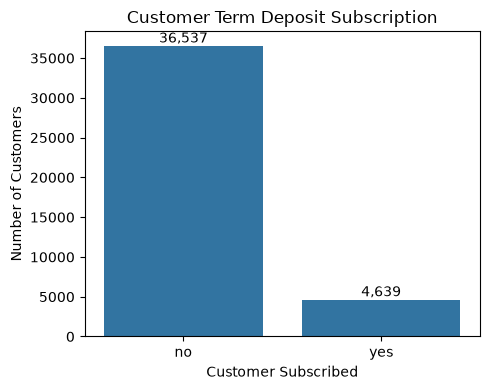

In [27]:
# Count how many customers subscribed and did not subscribe
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=bank_df, x="customer subscribed")

plt.title("Customer Term Deposit Subscription")
plt.xlabel("Customer Subscribed")
plt.ylabel("Number of Customers")

# Add the count above each bar
for bar in ax.patches:
    count = int(bar.get_height())

    ax.annotate(
        f"{count:,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [28]:
# Count each pdays value
print("pdays Value Counts:")
print(bank_df["pdays"].value_counts().head(15))

# Count customers who were not previously contacted
not_previously_contacted = (bank_df["pdays"] == 999).sum()

print(
    "\nCustomers not previously contacted:",
    not_previously_contacted
)

pdays Value Counts:
pdays
999    39661
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
Name: count, dtype: int64

Customers not previously contacted: 39661


In [29]:
quality_summary = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows",
        "Customers Not Previously Contacted",
        "Positive Target Cases (yes)",
        "Negative Target Cases (no)"
    ],
    "Result": [
        bank_df.shape[0],
        bank_df.shape[1],
        int(bank_df.isnull().sum().sum()),
        int(bank_df.duplicated().sum()),
        int((bank_df["pdays"] == 999).sum()),
        int((bank_df["customer subscribed"] == "yes").sum()),
        int((bank_df["customer subscribed"] == "no").sum())
    ]
})

display(quality_summary)

,Check,Result
0,Total Rows,41176
1,Total Columns,21
2,Missing Values,0
3,Duplicate Rows,0
4,Customers Not Previously Contacted,39661
5,Positive Target Cases (yes),4639
6,Negative Target Cases (no),36537


# Exploratory Data Analysis (EDA)

In [30]:
# Descriptive Statistics
# Summary statistics for numerical columns
display(bank_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


In [31]:
# Summary statistics for categorical columns
display(bank_df.describe(include="object").T)

C:\Users\Hp\AppData\Local\Temp\ipykernel_9956\1301063026.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(bank_df.describe(include="object").T)


,count,unique,top,freq
job,41176,12,admin.,10419
marital,41176,4,married,24921
education,41176,8,university.degree,12164
default,41176,3,no,32577
housing,41176,3,yes,21571
loan,41176,3,no,33938
contact,41176,2,cellular,26135
month,41176,10,may,13767
day_of_week,41176,5,thu,8618
poutcome,41176,3,nonexistent,35551


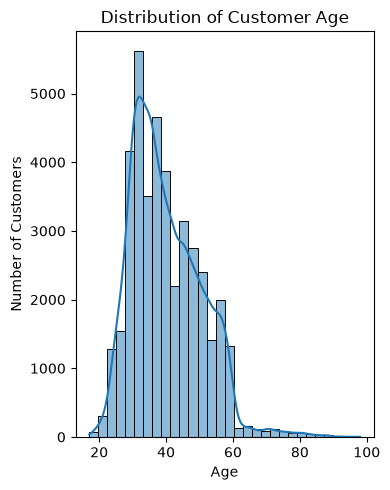

In [32]:
# Customer Age Analysis
# Age distribution
plt.figure(figsize=(4, 5))

sns.histplot(data=bank_df,x="age",bins=30,kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [33]:
# Create age groups temporarily for this analysis
# pd.cut() places each customer's age into one of the specified ranges
age_bins = [0, 25, 35, 45, 55, 65, 100]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
age_group = pd.cut(bank_df["age"], bins=age_bins, labels=age_labels)
age_group.name = "age_group"

# Count total customers and subscribers in each age group
age_analysis = bank_df.groupby(age_group, observed=False)["customer subscribed"].agg(Total_Customers="count",
                                                                                     Subscribers=lambda values: (values == "yes").sum())

# Calculate the percentage of customers who subscribed
age_analysis["Subscription_Rate_%"] = (age_analysis["Subscribers"] / age_analysis["Total_Customers"] * 100).round(2)

display(age_analysis)

,Total_Customers,Subscribers,Subscription_Rate_%
age_group,,,
18-25,1665,349,20.96
26-35,14844,1740,11.72
36-45,12839,1092,8.51
46-55,8247,717,8.69
56-65,2963,451,15.22
66+,618,290,46.93


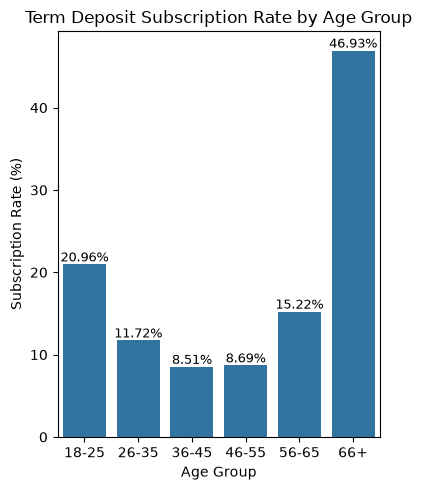

In [34]:
# Visualize subscription rates by age
plt.figure(figsize=(4, 5))

ax = sns.barplot(data=age_analysis.reset_index(),x="age_group",y="Subscription_Rate_%")

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

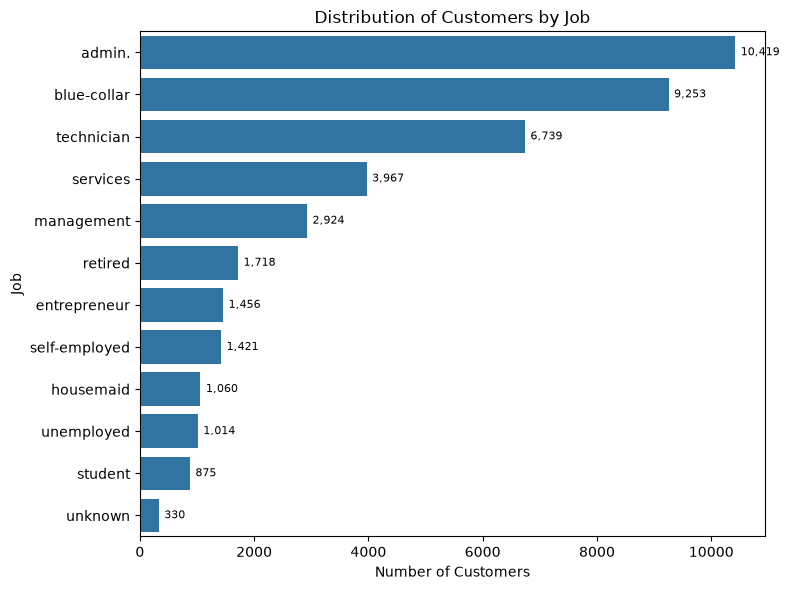

In [35]:
# Job Analysis
# Number of customers by occupation
job_counts = bank_df["job"].value_counts()

plt.figure(figsize=(8, 6))

ax = sns.countplot(data=bank_df,y="job",order=job_counts.index)

plt.title("Distribution of Customers by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job")

for bar in ax.patches:
    count = int(bar.get_width())

    ax.annotate(
        f"{count:,}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [36]:
# Calculate the total customers and subscribers for each job
job_analysis = bank_df.groupby("job")["customer subscribed"].agg(Total_Customers="count",Subscribers=lambda values: (values == "yes").sum())

# Calculate the subscription rate for each job
job_analysis["Subscription_Rate_%"] = (job_analysis["Subscribers"] / job_analysis["Total_Customers"] * 100).round(2)

display(job_analysis)

,Total_Customers,Subscribers,Subscription_Rate_%
job,,,
admin.,10419,1351,12.97
blue-collar,9253,638,6.90
entrepreneur,1456,124,8.52
housemaid,1060,106,10.00
management,2924,328,11.22
retired,1718,434,25.26
self-employed,1421,149,10.49
services,3967,323,8.14
student,875,275,31.43


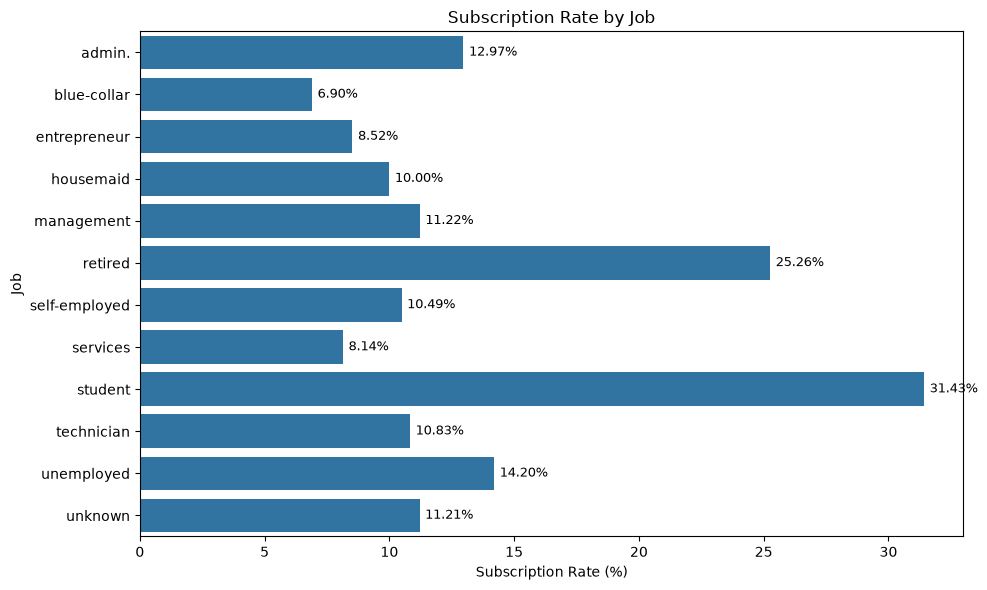

In [37]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(data=job_analysis.reset_index(),x="Subscription_Rate_%",y="job")

plt.title("Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")

for bar in ax.patches:
    width = bar.get_width()

    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [38]:
# Calculate subscription results for each education category
education_analysis = bank_df.groupby("education")["customer subscribed"].agg(Total_Customers="count",
                                                                             Subscribers=lambda values: (values == "yes").sum())

education_analysis["Subscription_Rate_%"] = (education_analysis["Subscribers"] / education_analysis["Total_Customers"] * 100).round(2)

display(education_analysis)

,Total_Customers,Subscribers,Subscription_Rate_%
education,,,
basic.4y,4176,428,10.25
basic.6y,2291,188,8.21
basic.9y,6045,473,7.82
high.school,9512,1031,10.84
illiterate,18,4,22.22
professional.course,5240,595,11.35
university.degree,12164,1669,13.72
unknown,1730,251,14.51


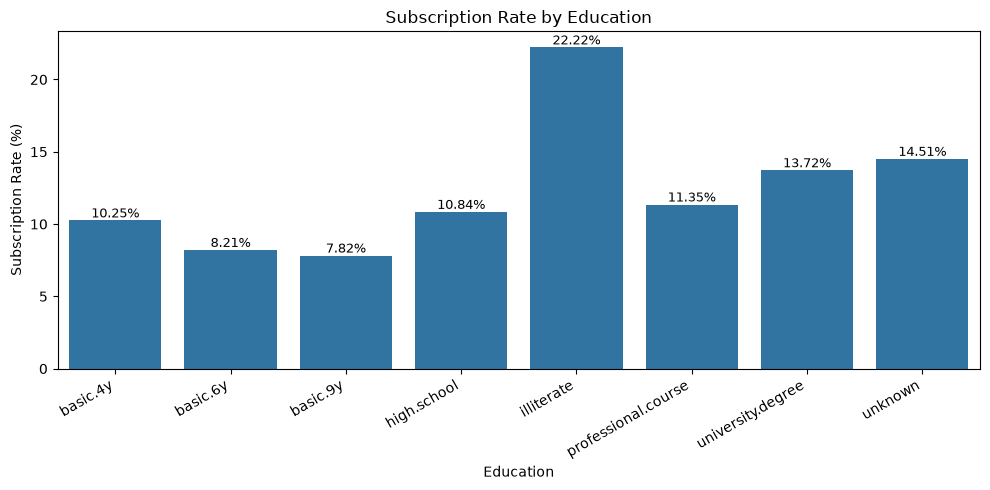

In [39]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(data=education_analysis.reset_index(),x="education",y="Subscription_Rate_%")

plt.title("Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=30, ha="right")

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [40]:
# Calculate subscription results for each marital status
marital_analysis = bank_df.groupby("marital")["customer subscribed"].agg(Total_Customers="count",Subscribers=lambda values: (values == "yes").sum())

marital_analysis["Subscription_Rate_%"] = (marital_analysis["Subscribers"] / marital_analysis["Total_Customers"] * 100).round(2)

display(marital_analysis)


,Total_Customers,Subscribers,Subscription_Rate_%
marital,,,
divorced,4611,476,10.32
married,24921,2531,10.16
single,11564,1620,14.01
unknown,80,12,15.00


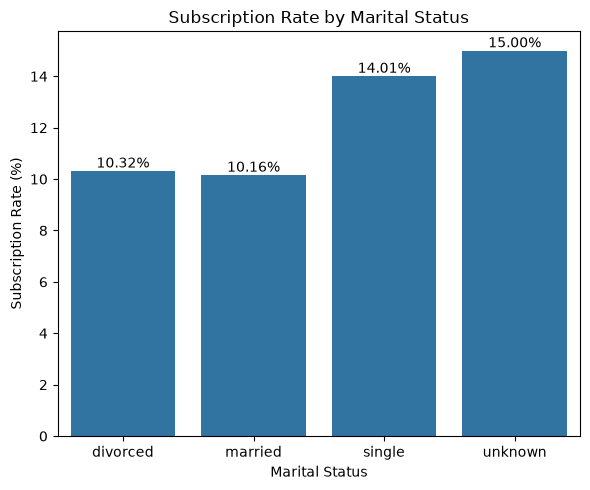

In [41]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(data=marital_analysis.reset_index(),x="marital",y="Subscription_Rate_%")

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [42]:
# Calculate subscription results for each contact method
contact_analysis = bank_df.groupby("contact")["customer subscribed"].agg(Total_Customers="count",Subscribers=lambda values: (values == "yes").sum())

contact_analysis["Subscription_Rate_%"] = (contact_analysis["Subscribers"] / contact_analysis["Total_Customers"] * 100).round(2)

display(contact_analysis)

,Total_Customers,Subscribers,Subscription_Rate_%
contact,,,
cellular,26135,3852,14.74
telephone,15041,787,5.23


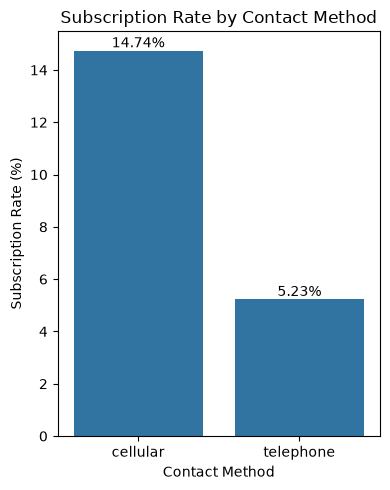

In [43]:
plt.figure(figsize=(4, 5))

ax = sns.barplot(data=contact_analysis.reset_index(),x="contact",y="Subscription_Rate_%")

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [44]:
# Calculate subscription results for each campaign month
month_analysis = bank_df.groupby("month")["customer subscribed"].agg(Total_Customers="count",Subscribers=lambda values: (values == "yes").sum())

month_analysis["Subscription_Rate_%"] = (month_analysis["Subscribers"] / month_analysis["Total_Customers"] * 100).round(2)

# Arrange the months in calendar order using a simple loop
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
ordered_months = []

for month in month_order:
    if month in month_analysis.index:
        ordered_months.append(month)

month_analysis = month_analysis.reindex(ordered_months)
display(month_analysis)

,Total_Customers,Subscribers,Subscription_Rate_%
month,,,
mar,546,276,50.55
apr,2631,539,20.49
may,13767,886,6.44
jun,5318,559,10.51
jul,7169,648,9.04
aug,6176,655,10.61
sep,570,256,44.91
oct,717,315,43.93
nov,4100,416,10.15


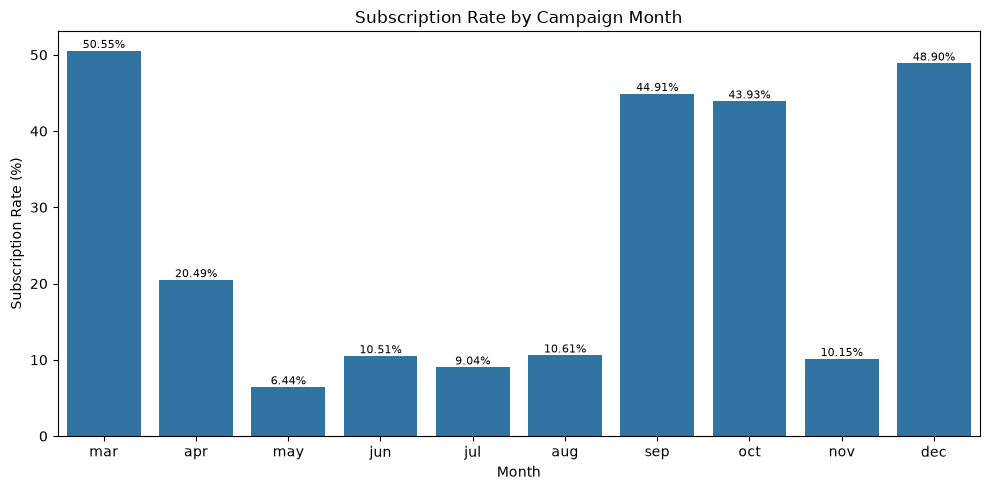

In [45]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(x=month_analysis.index,y=month_analysis["Subscription_Rate_%"])

plt.title("Subscription Rate by Campaign Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [46]:
# Calculate subscription results based on the previous campaign outcome
previous_outcome_analysis = bank_df.groupby("poutcome")["customer subscribed"].agg(Total_Customers="count",
                                                                                   Subscribers=lambda values: (values == "yes").sum())

previous_outcome_analysis["Subscription_Rate_%"] = (previous_outcome_analysis["Subscribers"] 
                                                    / previous_outcome_analysis["Total_Customers"] * 100).round(2)

display(previous_outcome_analysis)

,Total_Customers,Subscribers,Subscription_Rate_%
poutcome,,,
failure,4252,605,14.23
nonexistent,35551,3140,8.83
success,1373,894,65.11


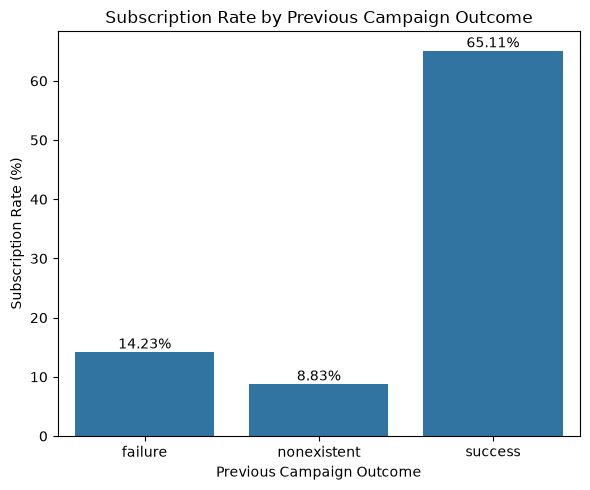

In [47]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(data=previous_outcome_analysis.reset_index(),x="poutcome",y="Subscription_Rate_%")

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [48]:
# Numerical Correlation Analysis
numeric_df = bank_df.select_dtypes(include="number")

print(numeric_df.columns.tolist())

['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


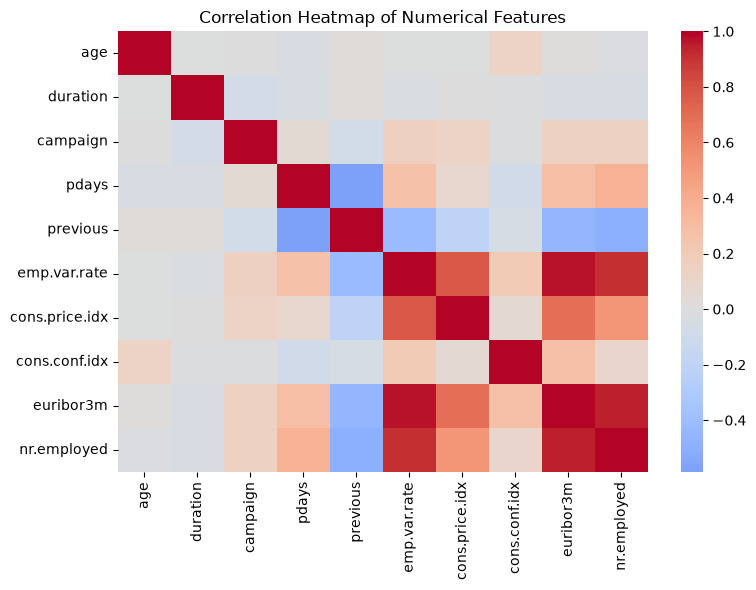

In [49]:
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix,cmap="coolwarm",center=0,annot=False)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Data Preprocessing and Feature Engineering

In [50]:
# Create a copy of the cleaned dataset
model_bank_df = bank_df.copy()

print("Original Dataset Shape:", bank_df.shape)
print("Working Dataset Shape:", model_bank_df.shape)

Original Dataset Shape: (41176, 21)
Working Dataset Shape: (41176, 21)


In [51]:
model_bank_df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'customer subscribed'],
      dtype='str')

In [52]:
# Convert the target labels into numbers: no = 0 and yes = 1
y = model_bank_df["customer subscribed"].map({"no": 0, "yes": 1})

# Select the input features for prediction
# Exclude "duration" because call duration is only known after the call ends.
X = model_bank_df.drop(columns=["customer subscribed", "duration"])

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (41176, 19)
Target shape: (41176,)

Target distribution:
customer subscribed
0    36537
1     4639
Name: count, dtype: int64


In [53]:
X.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
       'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
       'euribor3m', 'nr.employed'],
      dtype='str')

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)


In [55]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training Features: (32940, 19)
Testing Features: (8236, 19)

Training Target Distribution:
customer subscribed
0    0.8873
1    0.1127
Name: proportion, dtype: float64

Testing Target Distribution:
customer subscribed
0    0.8873
1    0.1127
Name: proportion, dtype: float64


In [56]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include="str").columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numeric_features))
print("Total categorical features:", len(categorical_features))


Numerical features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Total numerical features: 9
Total categorical features: 10


In [57]:
# Machine learning models need numerical input, so convert categories into columns of 0s and 1s
X_train_encoded = pd.get_dummies(X_train, dtype=int)
X_test_encoded = pd.get_dummies(X_test, dtype=int)

# Make sure the testing data has the same columns as the training data
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

Training data shape: (32940, 62)
Testing data shape: (8236, 62)


In [58]:
joblib.dump(X_train_encoded.columns.tolist(),"model_columns.pkl")

['model_columns.pkl']

# Model 1: Logistic Regression

In [59]:
# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42)

# Train the model using the training data
model.fit(X_train_encoded, y_train)

c:\Users\Hp\Desktop\Visual St\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [60]:
# Predict outcomes for the testing data
y_pred = model.predict(X_test_encoded)

print("Actual Values:")
print(y_test.head(10))

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
8489     0
40832    1
35671    0
35984    0
21954    0
11521    0
35048    0
31084    0
32870    0
22648    0
Name: customer subscribed, dtype: int64

Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [61]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display detailed performance
print(classification_report(y_test,y_pred,target_names=["No Subscription", "Subscription"]))

Model Accuracy: 82.75 %
                 precision    recall  f1-score   support

No Subscription       0.95      0.85      0.90      7308
   Subscription       0.35      0.65      0.46       928

       accuracy                           0.83      8236
      macro avg       0.65      0.75      0.68      8236
   weighted avg       0.88      0.83      0.85      8236



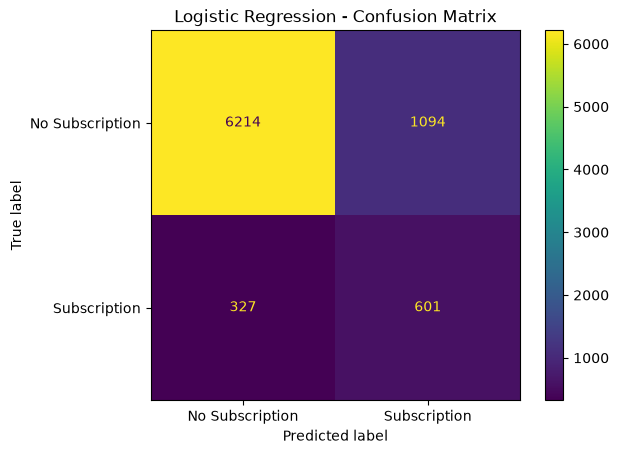

In [62]:
# Create a confusion matrix to compare actual and predicted results
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["No Subscription", "Subscription"])

display_cm.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Model 2: Decision Tree

In [63]:
tree_model = DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42)

tree_model.fit(X_train_encoded, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [64]:
y_pred_tree = tree_model.predict(X_test_encoded)

In [65]:
# Calculate accuracy
print("Decision Tree Accuracy:",round(accuracy_score(y_test, y_pred_tree) * 100, 2),"%")

print("\nClassification Report:")

# Display detailed performance
print(classification_report(y_test,y_pred_tree,target_names=["No Subscription", "Subscription"]))

Decision Tree Accuracy: 84.82 %

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.95      0.88      0.91      7308
   Subscription       0.39      0.63      0.48       928

       accuracy                           0.85      8236
      macro avg       0.67      0.75      0.70      8236
   weighted avg       0.89      0.85      0.86      8236



In [66]:
# Compare Logistic Regression and Decision Tree
model_comparison = pd.DataFrame({"Model": ["Logistic Regression", "Decision Tree"],

    "Accuracy": [accuracy_score(y_test, y_pred),accuracy_score(y_test, y_pred_tree)],

    "Subscription Precision": [precision_score(y_test, y_pred, zero_division=0),precision_score(y_test, y_pred_tree, zero_division=0)],

    "Subscription Recall": [recall_score(y_test, y_pred),recall_score(y_test, y_pred_tree)],

    "Subscription F1-Score": [f1_score(y_test, y_pred),f1_score(y_test, y_pred_tree)]
})

display(model_comparison.round(3))

,Model,Accuracy,Subscription Precision,Subscription Recall,Subscription F1-Score
0,Logistic Regression,0.827,0.355,0.648,0.458
1,Decision Tree,0.848,0.392,0.628,0.483


# Model 3: Random Forest

In [67]:
rf_model = RandomForestClassifier(n_estimators=100,max_depth=10,class_weight="balanced",random_state=42,n_jobs=-1)

rf_model.fit(X_train_encoded, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [68]:
y_pred_rf = rf_model.predict(X_test_encoded)

In [69]:
# Calculate accuracy
print("Random Forest Accuracy:",round(accuracy_score(y_test, y_pred_rf) * 100, 2),"%")

print("\nClassification Report:")

# Display detailed performance
print(classification_report(y_test,y_pred_rf,target_names=["No Subscription", "Subscription"]))

Random Forest Accuracy: 85.42 %

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.95      0.88      0.91      7308
   Subscription       0.41      0.64      0.50       928

       accuracy                           0.85      8236
      macro avg       0.68      0.76      0.71      8236
   weighted avg       0.89      0.85      0.87      8236



In [70]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression","Decision Tree","Random Forest"],

    "Accuracy": [accuracy_score(y_test, y_pred),accuracy_score(y_test, y_pred_tree),accuracy_score(y_test, y_pred_rf)],

    "Subscription Precision": [precision_score(y_test, y_pred, zero_division=0),precision_score(y_test, y_pred_tree, zero_division=0),precision_score(y_test, y_pred_rf, zero_division=0)],

    "Subscription Recall": [recall_score(y_test, y_pred),recall_score(y_test, y_pred_tree, zero_division=0),recall_score(y_test, y_pred_rf, zero_division=0)],

    "Subscription F1-Score": [f1_score(y_test, y_pred),f1_score(y_test, y_pred_tree, zero_division=0),f1_score(y_test, y_pred_rf, zero_division=0)]
})

display(model_comparison.round(3))

,Model,Accuracy,Subscription Precision,Subscription Recall,Subscription F1-Score
0,Logistic Regression,0.827,0.355,0.648,0.458
1,Decision Tree,0.848,0.392,0.628,0.483
2,Random Forest,0.854,0.406,0.639,0.497


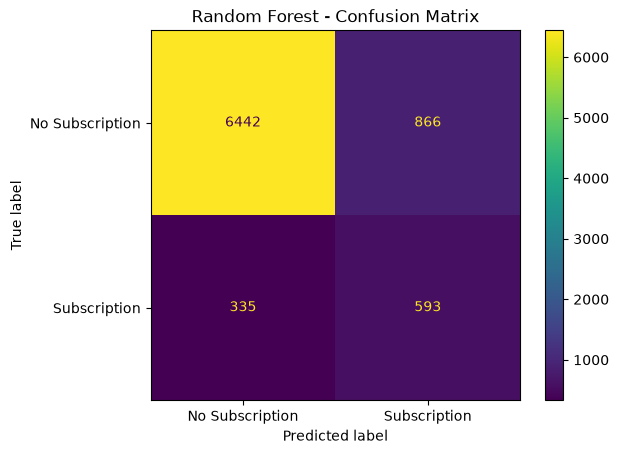

In [71]:
# Show the number of correct and incorrect predictions for each class
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_rf,display_labels=["No Subscription", "Subscription"])

plt.title("Random Forest - Confusion Matrix")
plt.show()

# Feature Importance

In [72]:
# Get the importance score for each feature from the Random Forest model
feature_importance = pd.DataFrame({"Feature": X_train_encoded.columns,"Importance": rf_model.feature_importances_})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)

# Display the 10 most important features
display(feature_importance.head(10).round(4))

,Feature,Importance
7,euribor3m,0.1716
8,nr.employed,0.1657
4,emp.var.rate,0.1299
6,cons.conf.idx,0.0775
61,poutcome_success,0.0481
2,pdays,0.0427
5,cons.price.idx,0.0381
50,month_may,0.0323
0,age,0.0305
43,contact_telephone,0.0232


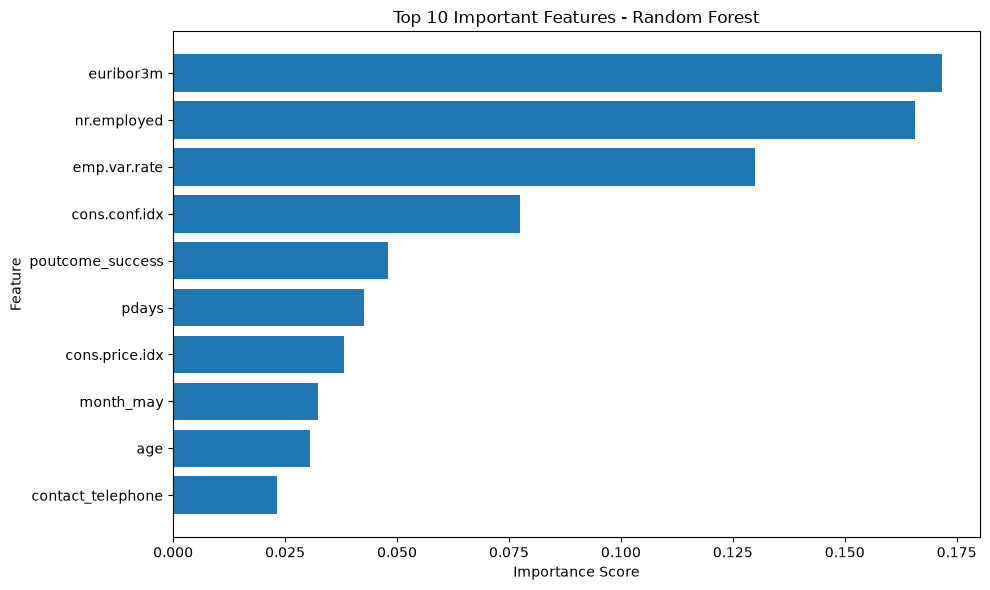

In [73]:
top_features = feature_importance.head(10).sort_values(by="Importance")

plt.figure(figsize=(10, 6))

plt.barh(top_features["Feature"],top_features["Importance"])

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - Random Forest")

plt.tight_layout()
plt.show()

In [74]:
joblib.dump(rf_model, "bank_marketing_random_forest.pkl")

['bank_marketing_random_forest.pkl']

# Conclusion

In [75]:
# The objective of this project was to predict:
# Whether a customer would subscribe to a term deposit based on information available in the Portuguese Bank Marketing dataset.

# Based on the current evaluation, Random Forest is a promising candidate because it provides the best balance between precision and recall among the three tested models.
# However, its subscription precision indicates that many customers predicted to subscribe did not actually subscribe.